# COVID-19 Deaths Analysis (JHU CSSE)

This notebook analyzes the JHU CSSE global time-series of cumulative COVID-19 deaths (22 Jan 2020 – 9 Mar 2023) across 201 countries. It answers six questions : which country had the most deaths, how this changes after adjusting for population, how deaths evolved over time, which months were the worst, which countries are currently rising or falling, and whether daily deaths can be forecasted.

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})

DATA_DIR = Path("/content")
DEATHS_FILE = Path(DATA_DIR) /"time_series_covid19_deaths_global.csv"
POP_FILE = Path(DATA_DIR) /"UID_ISO_FIPS_LookUp_Table.csv"

##  Loading and cleaning the data
The raw file is in wide format: one row per country/province and one column per date, with cumulative death counts. Cleaning steps:
1. Sum provinces/states so that each country has a single row.
2. Convert date columns to a proper datetime index and sort it.
3. Compute daily deaths with `diff()` of the cumulative series.
4. Clip negative daily values to 0. 80 countries have at least one decrease in their cumulative series, which are data corrections rather than "negative deaths".
5. Compute a 7-day moving average to remove weekday reporting effects.

There are no missing values in the raw data.

In [17]:
raw = pd.read_csv(DEATHS_FILE)
print("shape:", raw.shape)
raw.iloc[:10, :8]

shape: (289, 1147)


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0
1,NaN,Albania,41.15330,20.168300,0,0,0,0
2,NaN,Algeria,28.03390,1.659600,0,0,0,0
3,NaN,Andorra,42.50630,1.521800,0,0,0,0
4,NaN,Angola,-11.20270,17.873900,0,0,0,0
5,NaN,Antarctica,-71.94990,23.347000,0,0,0,0
6,NaN,Antigua and Barbuda,17.06080,-61.796400,0,0,0,0
7,NaN,Argentina,-38.41610,-63.616700,0,0,0,0
8,NaN,Armenia,40.06910,45.038200,0,0,0,0
9,Australian Capital Territory,Australia,-35.47350,149.012400,0,0,0,0


In [18]:
date_cols = raw.columns[4:]                     # Province/State, Country/Region, Lat, Long | dates...

# 1) sum provinces -> one row per country (cumulative deaths)
cum = raw.groupby("Country/Region")[list(date_cols)].sum().T
cum.index = pd.to_datetime(cum.index, format="%m/%d/%y")
cum = cum.sort_index()
cum.index.name = "date"

# 2) daily deaths: diff of cumulative; negatives are data corrections -> clip to 0
daily = cum.diff().fillna(cum.iloc[0]).clip(lower=0)

# 3) 7-day moving average smooths weekday reporting patterns
daily_ma7 = daily.rolling(7, min_periods=1).mean()

print("period:", cum.index.min().date(), "->", cum.index.max().date(), "| countries:", cum.shape[1])
print("missing values:", int(raw[list(date_cols)].isna().sum().sum()))
print("countries with decreasing cumulative series (corrections):", int((cum.diff() < 0).any().sum()))

period: 2020-01-22 -> 2023-03-09 | countries: 201
missing values: 0
countries with decreasing cumulative series (corrections): 80


## Q1. Which countries had the most total deaths?
Total deaths per country are taken from the last cumulative value and the top 10 are plotted.

**Finding:** the US is far ahead with about 1.12 million deaths, followed by Brazil (699k), India (531k), Russia (388k) and Mexico (333k). The top 10 countries account for 58.7% of all reported deaths worldwide. Absolute numbers mostly reflect population size, which motivates the next question.

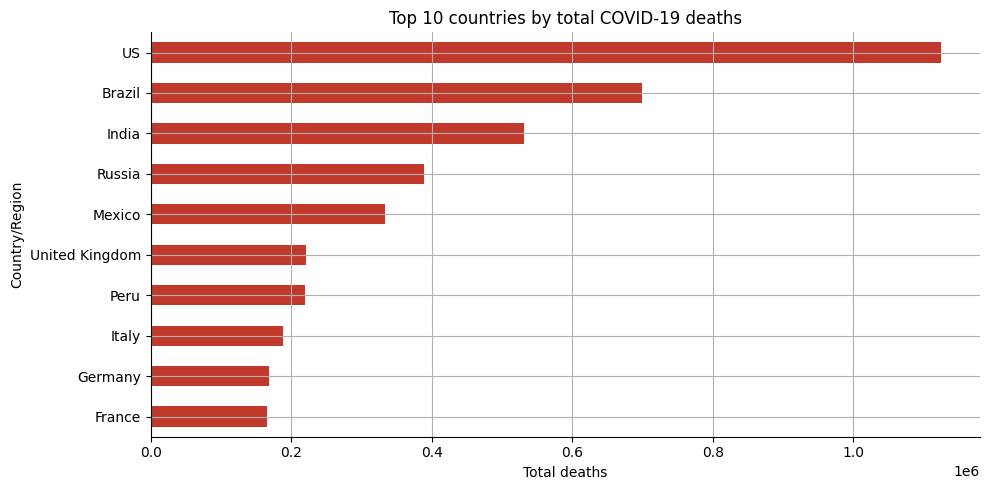

share of top 10 in global deaths: 58.7%


,total_deaths
Country/Region,
US,1123836
Brazil,699276
India,530779
Russia,388478
Mexico,333188
United Kingdom,220721
Peru,219539
Italy,188322
Germany,168935


In [19]:
total = cum.iloc[-1].sort_values(ascending=False)
top10 = total.head(10)

ax = top10.sort_values().plot.barh(color="#c0392b")
ax.set_title("Top 10 countries by total COVID-19 deaths")
ax.set_xlabel("Total deaths")
plt.tight_layout(); plt.show()

print("share of top 10 in global deaths: %.1f%%" % (100 * top10.sum() / total.sum()))
top10.to_frame("total_deaths")

## Q2. What changes after adjusting for population?
Absolute counts are not comparable between large and small countries, so I compute deaths per 100,000 people using population from the JHU lookup table. Countries with fewer than 1 million people are excluded to avoid noisy rates. Five countries could not be matched to a population and are dropped from this analysis.

**Finding:** the ranking changes completely. Peru is first with about 666 deaths per 100k, followed mostly by Eastern European countries: Bulgaria (550), Hungary (505), Bosnia and Herzegovina (496) and North Macedonia (464). Only Peru was in the absolute top 10 (7th). The US, first in absolute numbers, does not appear in the per-capita top 10.

countries without population: 5


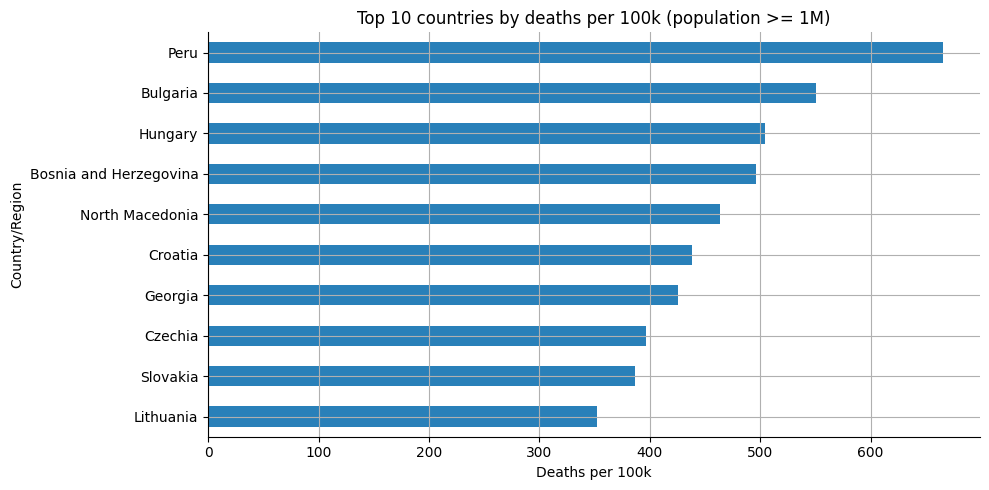

,total_deaths,population,deaths_per_100k,rank_abs,rank_pc
Country/Region,,,,,
Peru,219539,32971846.0,665.8,7.0,1.0
Bulgaria,38228,6948445.0,550.2,29.0,2.0
Hungary,48762,9660350.0,504.8,26.0,3.0
Bosnia and Herzegovina,16280,3280815.0,496.2,58.0,4.0
North Macedonia,9662,2083380.0,463.8,67.0,5.0
Croatia,17987,4105268.0,438.1,52.0,6.0
Georgia,16971,3989175.0,425.4,55.0,7.0
Czechia,42491,10708982.0,396.8,28.0,8.0
Slovakia,21035,5434712.0,387.0,46.0,9.0


In [20]:
if (POP_FILE).exists():
 lk = pd.read_csv(POP_FILE)
 country_rows = lk[lk["Province_State"].isna()].groupby("Country_Region")["Population"].sum()
 prov_sum = lk.groupby("Country_Region")["Population"].sum()
 pop = prov_sum.copy()
 pop.update(country_rows)                       # prefer the national-level row when it exists
 pop = pop[pop > 0]

 df = pd.DataFrame({"total_deaths": total}).join(pop.rename("population"), how="left")
 print("countries without population:", df["population"].isna().sum())
 df = df[df["population"] >= 1_000_000].copy()
 df["deaths_per_100k"] = df["total_deaths"] / df["population"] * 1e5

    # how much does the ranking change after normalising?
 df["rank_abs"] = df["total_deaths"].rank(ascending=False)
 df["rank_pc"] = df["deaths_per_100k"].rank(ascending=False)
 top_pc = df.sort_values("deaths_per_100k", ascending=False).head(10)
 ax = top_pc["deaths_per_100k"].sort_values().plot.barh(color="#2980b9")
 ax.set_title("Top 10 countries by deaths per 100k (population >= 1M)")
 ax.set_xlabel("Deaths per 100k")
 plt.tight_layout(); plt.show()

 display(top_pc[["total_deaths", "population", "deaths_per_100k", "rank_abs", "rank_pc"]].round(1))
else:
    print("UID_ISO_FIPS_LookUp_Table.csv not found in data/ -> skipping Q2")

## Q3. How did daily deaths evolve, and when was the peak?
Daily deaths (7-day moving average) are plotted for the five countries with the most total deaths, and the peak date is computed for the top 10.

**Finding:** countries peaked at very different times. Italy and France peaked in spring 2020 (April), the US, UK and Germany in January 2021, Mexico in February 2021, Brazil and Peru in April 2021, India in May 2021 (the highest peak, about 4,190 deaths/day) and Russia as late as November 2021. There is no single global peak; the pandemic moved through regions in waves.

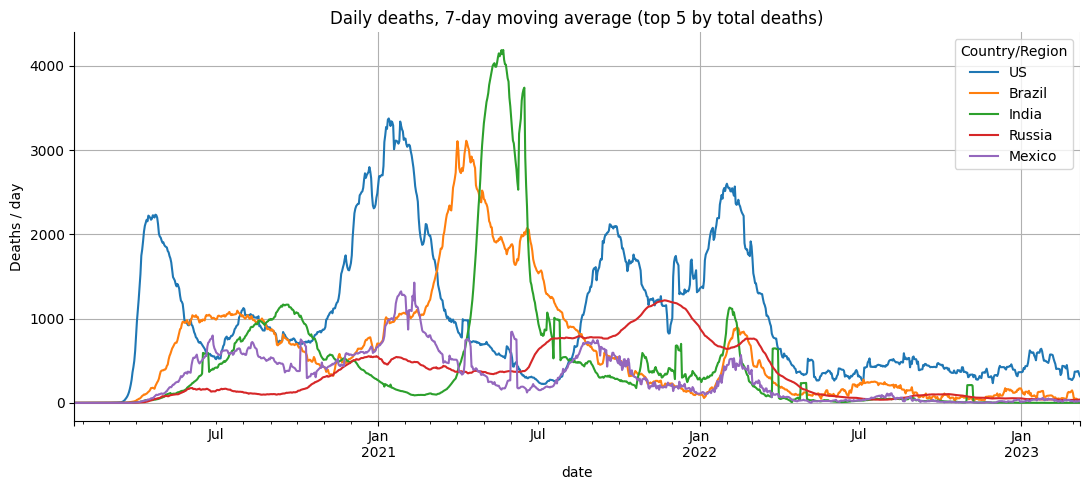

,peak_date,peak_daily_deaths_ma7
Country/Region,,
US,2021-01-13,3377.0
Brazil,2021-04-11,3112.0
India,2021-05-23,4190.0
Russia,2021-11-22,1218.0
Mexico,2021-02-11,1428.0
United Kingdom,2021-01-22,1396.0
Peru,2021-04-23,874.0
Italy,2020-04-02,814.0
Germany,2021-01-14,896.0


In [21]:
top5 = top10.index[:5]
ax = daily_ma7[top5].plot(figsize=(11, 5))
ax.set_title("Daily deaths, 7-day moving average (top 5 by total deaths)")
ax.set_ylabel("Deaths / day")
plt.tight_layout(); plt.show()

peaks = pd.DataFrame({
    "peak_date": daily_ma7[top10.index].idxmax(),
    "peak_daily_deaths_ma7": daily_ma7[top10.index].max().round(0),
})
peaks

## Q4. Which months were the worst globally?
Daily deaths of all countries are summed and aggregated by month.

**Finding:** the deadliest month was January 2021 (about 422k deaths), followed by May 2021 (379k), April 2021 (379k), December 2020 (357k) and February 2021 (311k). The winter 2020–21 wave and the Delta wave in spring 2021 together explain most of the peak months.

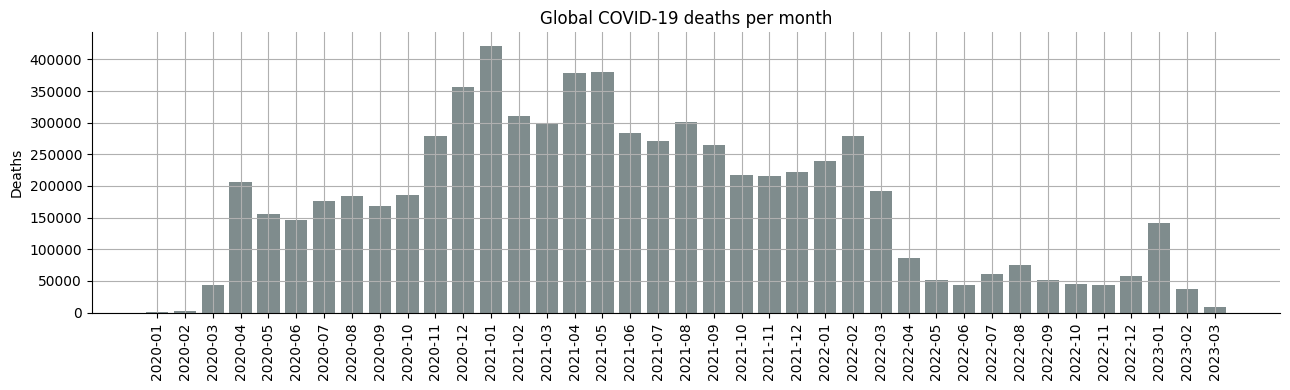

Worst 5 months:


,deaths
date,
2021-01-01,421692.0
2021-05-01,379446.0
2021-04-01,379148.0
2020-12-01,356809.0
2021-02-01,311232.0


In [22]:
world_daily = daily.sum(axis=1)
monthly = world_daily.resample("MS").sum()

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(monthly.index.strftime("%Y-%m"), monthly.values, color="#7f8c8d")
ax.tick_params(axis="x", rotation=90)
ax.set_title("Global COVID-19 deaths per month"); ax.set_ylabel("Deaths")
plt.tight_layout(); plt.show()

print("Worst 5 months:")
monthly.sort_values(ascending=False).head(5).rename("deaths").to_frame()

## Q5. Which countries are currently rising or falling?
I compare the latest 7-day average of daily deaths with the value 30 days earlier, keeping only countries that had at least 10 deaths/day in the earlier period.

**Finding:** no country in this comparison is actually rising; the "rising" table lists the countries with the smallest decline (Russia −5.5%, Austria −6.6%, Germany −7.1%). The data ends in March 2023, when the pandemic was in its tail phase. Several −100% values (United Kingdom, Taiwan) are most likely due to countries stopping or changing their reporting rather than a real drop to zero, so this result should be interpreted with care.

In [25]:
now = daily_ma7.iloc[-1]
before = daily_ma7.iloc[-31]
chg = pd.DataFrame({"ma7_before": before, "ma7_now": now})
chg = chg[chg["ma7_before"] >= 10].copy()
chg["pct_change"] = (chg["ma7_now"] / chg["ma7_before"] - 1) * 100
chg = chg.sort_values("pct_change")

print("Fastest declining:");  display(chg.head(5).round(1))
print("Slowest declining:");     display(chg.tail(5).iloc[::-1].round(1))

Fastest declining:


,ma7_before,ma7_now,pct_change
Country/Region,,,
United Kingdom,65.4,0.0,-100.0
Taiwan*,69.6,0.0,-100.0
China,475.3,0.7,-99.8
Brazil,65.6,11.3,-82.8
Peru,40.4,8.7,-78.4


Slowest declining:


,ma7_before,ma7_now,pct_change
Country/Region,,,
Russia,41.9,39.6,-5.5
Austria,10.9,10.1,-6.6
Germany,98.3,91.3,-7.1
Canada,34.0,26.3,-22.7
Chile,14.6,10.9,-25.5


## Q6. Can daily deaths be forecasted?
Setup for the US:
- **Time-based split:** the last 28 days are held out as the test set (no random shuffling, which would leak future information).
- **Target:** the 7-day moving average of daily deaths.
- **Model:** Ridge regression using the previous 14 values as features, with recursive multi-step forecasting. Each prediction is fed back as an input for the next day, so the evaluation reflects a real 28-day-ahead forecast.
- **Baselines:** repeat the last observed value, and repeat the mean of the last 7 days.
- **Metrics:** MAE and RMSE on the test period.

**Finding:** the simple "last value" baseline is the best model (MAE 96.9, RMSE 111.5). The Ridge model is worse (MAE 122.8, RMSE 146.5), and the 7-day-mean baseline is the worst. A flexible model does not automatically beat a naive one: the series is smooth and declining in the test window, and recursive forecasting accumulates error over 28 steps.

,model,MAE,RMSE
0,naive (last value),96.86,111.52
1,mean of last 7d,173.78,182.36
2,Ridge on 14 lags,122.78,146.52


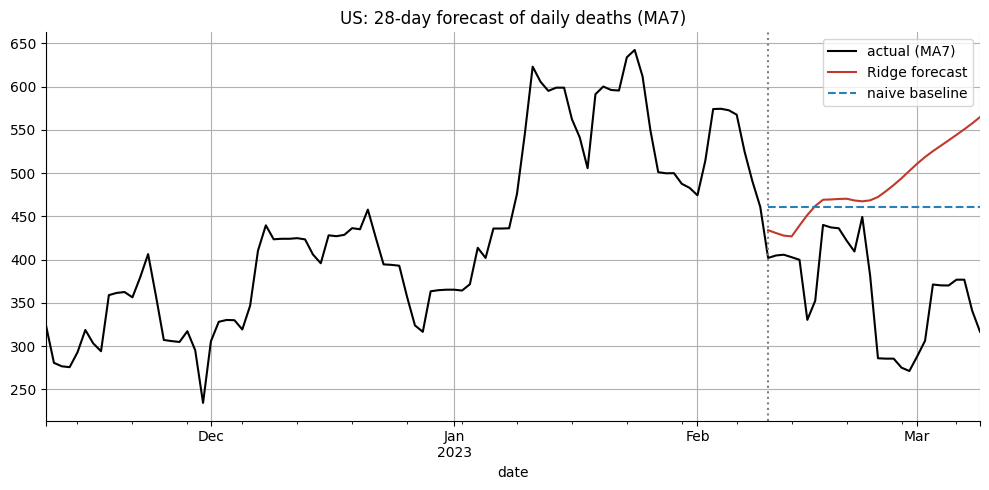

In [24]:
COUNTRY, HORIZON, N_LAGS = "US", 28, 14

y = daily_ma7[COUNTRY].copy()
train, test = y.iloc[:-HORIZON], y.iloc[-HORIZON:]

def make_xy(series, n_lags):
    X = np.column_stack([series.shift(k) for k in range(1, n_lags + 1)])
    ok = ~np.isnan(X).any(axis=1)
    return X[ok], series.values[ok]

X_tr, y_tr = make_xy(train, N_LAGS)
model = Ridge(alpha=1.0).fit(X_tr, y_tr)

# recursive multi-step forecast
hist = list(train.values[-N_LAGS:])
preds = []
for _ in range(HORIZON):
    x = np.array(hist[-N_LAGS:][::-1]).reshape(1, -1)   # lag1 = most recent
    p = max(model.predict(x)[0], 0)
    preds.append(p); hist.append(p)
pred_model = pd.Series(preds, index=test.index)

# baselines
pred_naive = pd.Series(train.iloc[-1], index=test.index)                     # repeat last value
pred_mean7 = pd.Series(train.iloc[-7:].mean(), index=test.index)             # mean of last 7 days

def report(name, p):
    return {"model": name,
            "MAE": mean_absolute_error(test, p),
            "RMSE": mean_squared_error(test, p) ** 0.5}

res = pd.DataFrame([report("naive (last value)", pred_naive),
                    report("mean of last 7d", pred_mean7),
                    report("Ridge on 14 lags", pred_model)]).round(2)
display(res)

ax = y.iloc[-120:].plot(label="actual (MA7)", color="black")
pred_model.plot(ax=ax, label="Ridge forecast", color="#c0392b")
pred_naive.plot(ax=ax, label="naive baseline", color="#2980b9", ls="--")
ax.axvline(test.index[0], color="gray", ls=":")
ax.set_title(f"{COUNTRY}: {HORIZON}-day forecast of daily deaths (MA7)")
ax.legend(); plt.tight_layout(); plt.show()

## Conclusions

**Key findings**
- **Total deaths:** the US (1.12M), Brazil (699k) and India (531k) lead in absolute terms. The top 10 countries account for 58.7% of reported deaths.
- **Adjusted for population:** the picture reverses. Peru (about 666 deaths per 100k) and several Eastern European countries (Bulgaria, Hungary, Bosnia and Herzegovina, North Macedonia) were hit hardest, while the US is no longer in the top 10. Absolute counts alone are misleading for comparing countries.
- **Timing:** peaks were not synchronized. Italy and France peaked in spring 2020, most others in winter 2020–21 or spring 2021, and Russia in November 2021.
- **Worst months worldwide:** January 2021 (about 422k deaths), May 2021 and April 2021 (about 379k each).
- **Recent trend:** by the end of the data, deaths were declining almost everywhere. Some drops to zero reflect reporting changes, not real zeros.
- **Forecasting:** for the US 28-day horizon, a naive last-value baseline (MAE 96.9) outperformed a Ridge model with lag features (MAE 122.8).

**Limitations**
- Reported deaths depend on each country's testing and reporting practices (under-reporting, delays, definition changes), so cross-country comparisons are approximate.
- Five countries have no matched population and are missing from the per-capita analysis.
- Reporting changes (e.g. the UK, Taiwan) create artificial zeros in the final weeks.
- Population is a single static value, and age structure is not considered.
- The forecast uses only the history of one series and was evaluated on one country and one 28-day window, so the result may not generalize.

**Possible next steps**
- Evaluate forecasts with rolling-origin (walk-forward) validation over several windows and countries.
- Try models that capture trend and seasonality (ARIMA, Prophet, gradient boosting with calendar features).
- Add confirmed cases and vaccination data to study relationships between cases, vaccination and deaths.
- Cluster countries by the shape of their death curves (e.g. K-means on normalized 7-day averages).